In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("sales_data.csv")

In [9]:
df.head()

,Order_ID,Date,Region,State,Category,Product,Quantity,Sales,Profit
0,ORD-2024-00381,2024-01-04,Asia Pacific,Seoul,Technology,Tablet,1,1740.96,470.08
1,ORD-2025-00773,2024-01-04,North America,New York,Technology,Monitor,3,3675.08,907.42
2,ORD-2025-00901,2024-01-04,North America,Florida,Appliances,Coffee Maker,8,2657.64,513.85
3,ORD-2025-00846,2024-01-04,North America,Florida,Technology,Smartphone,8,8451.91,1820.99
4,ORD-2024-00465,2024-01-05,Europe,Bavaria,Office Supplies,Notebook,2,135.73,39.07


In [10]:
df.shape

(1200, 9)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Order_ID  1200 non-null   object 
 1   Date      1200 non-null   object 
 2   Region    1200 non-null   object 
 3   State     1200 non-null   object 
 4   Category  1200 non-null   object 
 5   Product   1200 non-null   object 
 6   Quantity  1200 non-null   int64  
 7   Sales     1200 non-null   float64
 8   Profit    1200 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 84.5+ KB


In [12]:
df.isnull().sum()

Order_ID    0
Date        0
Region      0
State       0
Category    0
Product     0
Quantity    0
Sales       0
Profit      0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [16]:
df.describe()

,Quantity,Sales,Profit
count,1200.000000,1200.000000,1200.000000
mean,6.115000,3614.656892,594.163008
std,3.224196,3833.218389,855.069521
min,1.000000,10.680000,-4032.110000
25%,3.000000,646.242500,101.085000
50%,6.000000,2186.175000,307.735000
75%,9.000000,5357.025000,900.250000
max,11.000000,18483.150000,4793.620000


In [18]:
df.columns

Index(['Order_ID', 'Date', 'Region', 'State', 'Category', 'Product',
       'Quantity', 'Sales', 'Profit'],
      dtype='object')

In [20]:
df.select_dtypes(include=np.number).columns

Index(['Quantity', 'Sales', 'Profit'], dtype='object')

In [22]:
df.select_dtypes(include='object').columns

Index(['Order_ID', 'Date', 'Region', 'State', 'Category', 'Product'], dtype='object')

In [24]:
df.dtypes

Order_ID     object
Date         object
Region       object
State        object
Category     object
Product      object
Quantity      int64
Sales       float64
Profit      float64
dtype: object

In [26]:
df['Date'] = pd.to_datetime(df['Date'])

In [28]:
df[['Sales', 'Quantity', 'Profit']].describe()

,Sales,Quantity,Profit
count,1200.000000,1200.000000,1200.000000
mean,3614.656892,6.115000,594.163008
std,3833.218389,3.224196,855.069521
min,10.680000,1.000000,-4032.110000
25%,646.242500,3.000000,101.085000
50%,2186.175000,6.000000,307.735000
75%,5357.025000,9.000000,900.250000
max,18483.150000,11.000000,4793.620000


In [29]:
df[['Sales', 'Quantity', 'Profit']].lt(0).sum()

Sales        0
Quantity     0
Profit      68
dtype: int64

In [30]:
df[['Sales', 'Quantity', 'Profit']].eq(0).sum()

Sales       0
Quantity    0
Profit      0
dtype: int64

In [32]:
for col in ['Sales', 'Quantity', 'Profit']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, "Outliers:", len(outliers))

Sales Outliers: 57
Quantity Outliers: 0
Profit Outliers: 86


In [34]:
print("Start Date:", df['Date'].min())
print("End Date:", df['Date'].max())

Start Date: 2024-01-04 00:00:00
End Date: 2025-12-31 00:00:00


In [36]:
categorical_cols = ['Region', 'State', 'Category', 'Product']

In [38]:
for col in categorical_cols:
    df[col] = df[col].astype('category')

In [40]:
df['Year'] = df['Date'].dt.year

In [42]:
df['Month'] = df['Date'].dt.month

In [44]:
df['Month_Name'] = df['Date'].dt.month_name()

In [46]:
df.head()

,Order_ID,Date,Region,State,Category,Product,Quantity,Sales,Profit,Year,Month,Month_Name
0,ORD-2024-00381,2024-01-04,Asia Pacific,Seoul,Technology,Tablet,1,1740.96,470.08,2024,1,January
1,ORD-2025-00773,2024-01-04,North America,New York,Technology,Monitor,3,3675.08,907.42,2024,1,January
2,ORD-2025-00901,2024-01-04,North America,Florida,Appliances,Coffee Maker,8,2657.64,513.85,2024,1,January
3,ORD-2025-00846,2024-01-04,North America,Florida,Technology,Smartphone,8,8451.91,1820.99,2024,1,January
4,ORD-2024-00465,2024-01-05,Europe,Bavaria,Office Supplies,Notebook,2,135.73,39.07,2024,1,January


In [48]:
df.dtypes

Order_ID              object
Date          datetime64[ns]
Region              category
State               category
Category            category
Product             category
Quantity               int64
Sales                float64
Profit               float64
Year                   int32
Month                  int32
Month_Name            object
dtype: object

In [50]:
df.shape

(1200, 12)

In [53]:
df.isnull().sum()

Order_ID      0
Date          0
Region        0
State         0
Category      0
Product       0
Quantity      0
Sales         0
Profit        0
Year          0
Month         0
Month_Name    0
dtype: int64

# EDA

In [55]:
category_sales = df.groupby('Category', observed=True)['Sales'].sum().sort_values(ascending=False)
category_sales

Category
Technology         3072252.37
Furniture           810413.73
Appliances          349437.73
Office Supplies     105484.44
Name: Sales, dtype: float64

In [57]:
 category_profit = df.groupby('Category', observed=True)['Profit'].sum().sort_values(ascending=False)
category_profit

Category
Technology         528665.31
Furniture          106451.21
Appliances          51908.99
Office Supplies     25970.10
Name: Profit, dtype: float64

In [59]:
region_sales = df.groupby('Region', observed=True)['Sales'].sum().sort_values(ascending=False)
region_sales

Region
North America           1409451.82
Europe                  1082412.22
Asia Pacific             892309.29
Middle East & Africa     493790.08
Latin America            459624.86
Name: Sales, dtype: float64

In [61]:
region_profit = df.groupby('Region', observed=True)['Profit'].sum().sort_values(ascending=False)
region_profit

Region
North America           222647.41
Europe                  184937.10
Asia Pacific            148553.44
Latin America            81287.75
Middle East & Africa     75569.91
Name: Profit, dtype: float64

In [82]:
monthly_sales = df.groupby(['Year', 'Month', 'Month_Name'], observed=True)['Sales'].sum().reset_index()

monthly_sales['Month_Label'] = monthly_sales['Month_Name'].str[:3]

monthly_sales

,Year,Month,Month_Name,Sales,Month_Label
0,2024,1,January,165398.76,Jan
1,2024,2,February,132856.13,Feb
2,2024,3,March,195337.79,Mar
3,2024,4,April,185375.09,Apr
4,2024,5,May,188843.85,May
5,2024,6,June,121919.48,Jun
6,2024,7,July,229607.01,Jul
7,2024,8,August,221307.18,Aug
8,2024,9,September,110250.02,Sep
9,2024,10,October,143787.36,Oct


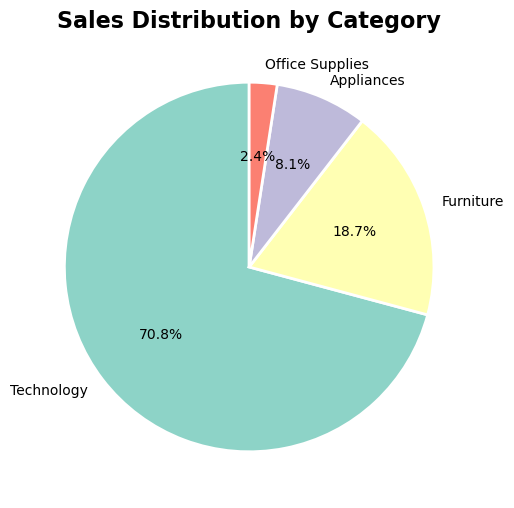

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9,6))

colors = plt.cm.Set3(range(len(category_sales)))

plt.pie(category_sales.values,labels=category_sales.index,autopct='%1.1f%%',startangle=90,colors=colors,wedgeprops={'edgecolor': 'white', 'linewidth': 2})

plt.title('Sales Distribution by Category', fontsize=16, fontweight='bold')
plt.show()

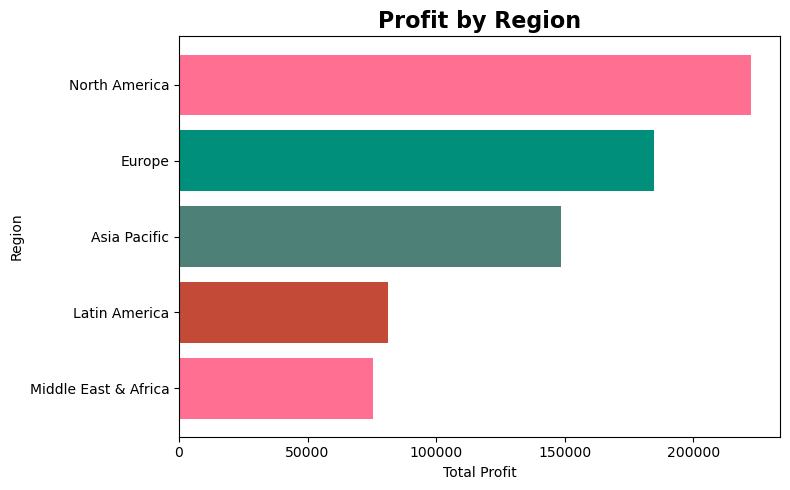

In [146]:
plt.figure(figsize=(8,5))

profit_sorted = region_profit.sort_values()

colors = ['#FF6F91', '#C34A36', '#4D8076', '#008F7A']

plt.barh(profit_sorted.index, profit_sorted.values,
         color=colors[:len(profit_sorted)])

plt.title('Profit by Region', fontsize=16, fontweight='bold')
plt.xlabel('Total Profit')
plt.ylabel('Region')

plt.tight_layout()
plt.show()

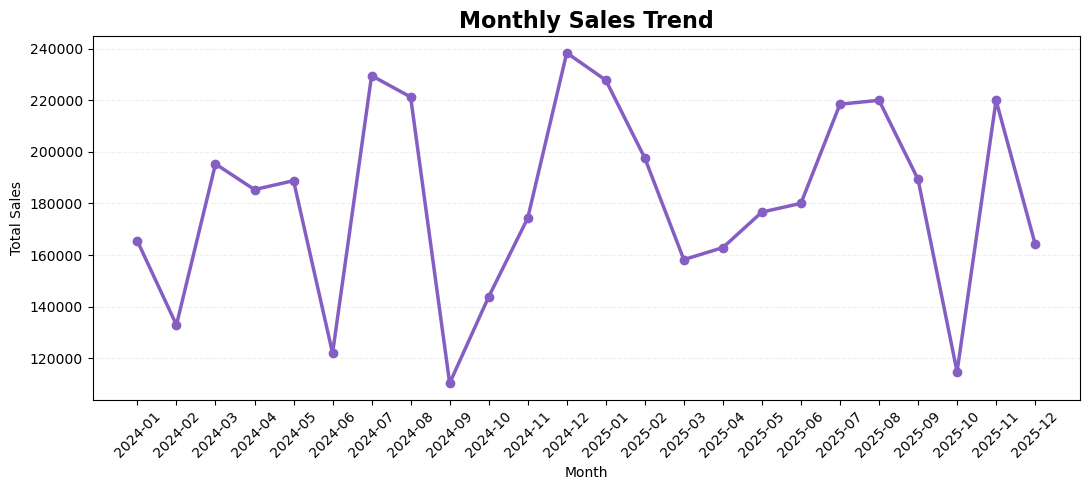

In [148]:
monthly_sales = (df.groupby(['Year', 'Month'], observed=True)['Sales'].sum().reset_index().sort_values(['Year', 'Month']))

monthly_sales['Period'] = (monthly_sales['Year'].astype(str) + '-' +monthly_sales['Month'].astype(str).str.zfill(2))

plt.figure(figsize=(11,5))

plt.plot(monthly_sales['Period'],monthly_sales['Sales'],marker='o',linewidth=2.5,color='#845EC2')

plt.title('Monthly Sales Trend', fontsize=16, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.2)

plt.tight_layout()
plt.show()

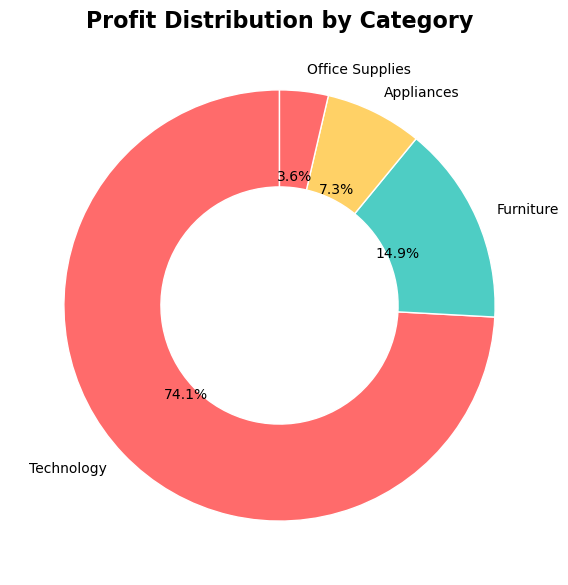

In [144]:
plt.figure(figsize=(7,7))

colors = ['#FF6B6B', '#4ECDC4', '#FFD166']

plt.pie(category_profit.values,labels=category_profit.index,autopct='%1.1f%%',startangle=90,colors=colors,wedgeprops={'width': 0.45, 'edgecolor': 'white'})

plt.title('Profit Distribution by Category', fontsize=16, fontweight='bold')
plt.show()

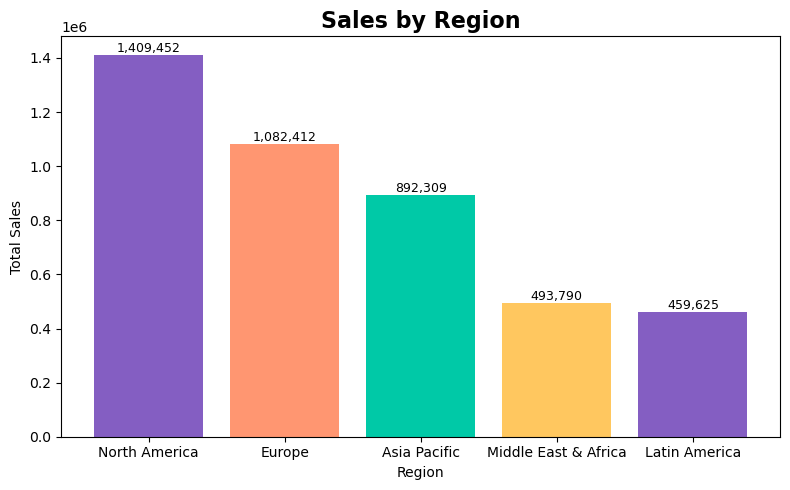

In [143]:
plt.figure(figsize=(8,5))

colors = ['#845EC2', '#FF9671', '#00C9A7', '#FFC75F']

plt.bar(region_sales.index, region_sales.values,color=colors[:len(region_sales)])

plt.title('Sales by Region', fontsize=16, fontweight='bold')
plt.xlabel('Region')
plt.ylabel('Total Sales')

for i, v in enumerate(region_sales.values):plt.text(i, v, f'{v:,.0f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

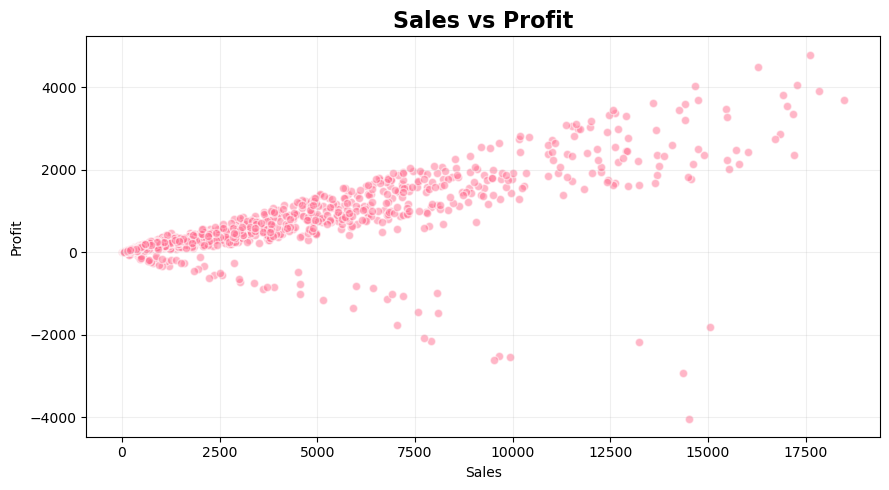

In [141]:
plt.figure(figsize=(9,5))

plt.scatter(df['Sales'],df['Profit'],alpha=0.5,color='#FF6F91',edgecolors='white')

plt.title('Sales vs Profit', fontsize=16, fontweight='bold')
plt.xlabel('Sales')
plt.ylabel('Profit')
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

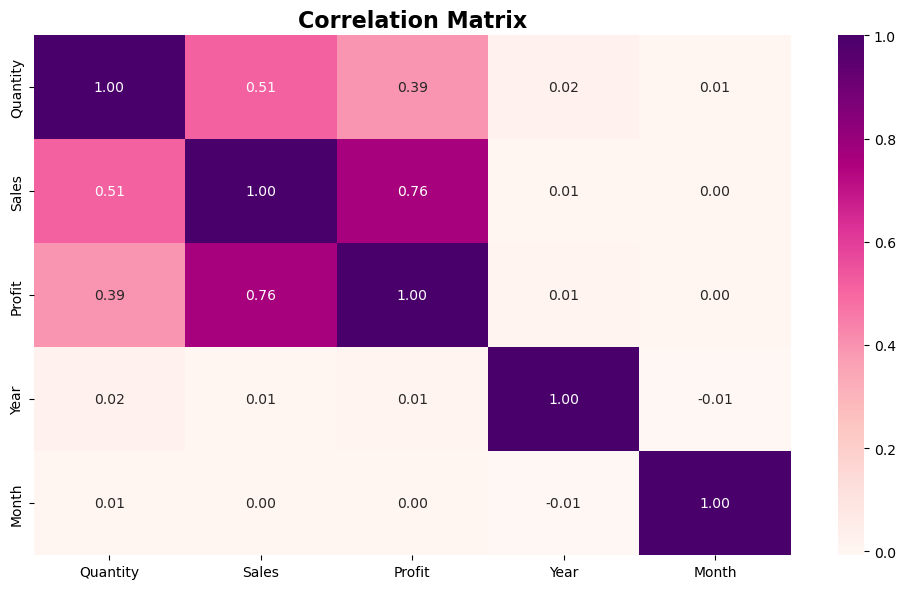

In [99]:
corr = df.select_dtypes(include='number').corr()

plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, cmap='RdPu', fmt='.2f')
plt.title('Correlation Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [101]:
print(df.columns.tolist())

['Order_ID', 'Date', 'Region', 'State', 'Category', 'Product', 'Quantity', 'Sales', 'Profit', 'Year', 'Month', 'Month_Name']


In [103]:
features = ['Quantity']
target = 'Sales'

X = df[features]
y = df[target]

print("Features:", X.columns.tolist())
print("Target:", target)

Features: ['Quantity']
Target: Sales


In [106]:
from sklearn.model_selection import train_test_split

In [108]:
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.3,random_state=1)

In [112]:
X_train

,Quantity
842,5
625,5
486,10
330,3
789,3
...,...
715,1
905,4
1096,11
235,8


In [114]:
X_test

,Quantity
636,7
683,10
1033,2
190,4
1083,4
...,...
1074,9
860,1
1098,5
5,3


In [116]:
y_train

842      2508.02
625      8350.81
486       310.77
330      1813.30
789      3039.15
          ...   
715      1713.10
905      1412.14
1096    13756.33
235      5812.14
1061       60.88
Name: Sales, Length: 840, dtype: float64

In [118]:
y_test

636      456.71
683     5878.23
1033    1083.10
190     1368.36
1083      94.37
         ...   
1074    3399.37
860      296.10
1098    3822.15
5       1801.17
1122     605.87
Name: Sales, Length: 360, dtype: float64

In [120]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (840, 1)
X_test shape: (360, 1)
y_train shape: (840,)
y_test shape: (360,)


In [122]:
from sklearn.linear_model import LinearRegression

In [125]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [127]:
print("Model training completed.")

Model training completed.


In [129]:
y_pred = model.predict(X_test)

print("Predictions completed.")
print(y_pred[:10])

Predictions completed.
[4215.55171045 6152.9891189   986.48936304 2278.114302   2278.114302
 4215.55171045  340.67689356 6152.9891189  1632.30183252 6798.80158838]


In [134]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [136]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

In [138]:
print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R² Score:", r2)

Mean Absolute Error: 2216.852274089169
Mean Squared Error: 9381862.667222595
Root Mean Squared Error: 3062.982642331261
R² Score: 0.21738519448762061


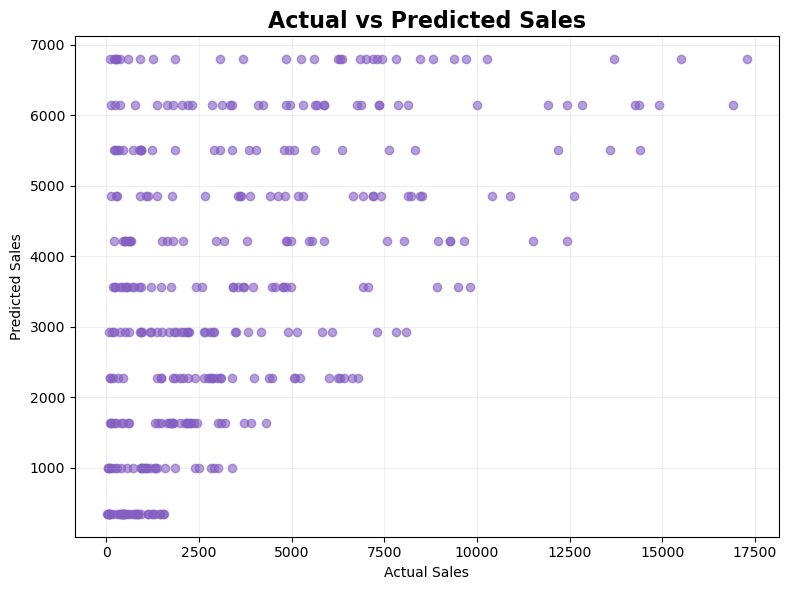

In [140]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6, color='#845EC2')

plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales', fontsize=16, fontweight='bold')

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()